# What is Standardization?

**Standardization** converts the data into a certain range(Generally betweeen -1 to 1) using formula of **Z-score**.
* **Z-score** = (x-mean) / std_deviation

* `For eg`: If there're two columns namely IQ and Salary ranging between 1-10 and 20,000-50,000 respectively, the machine learning algorithm will give more importance to salary.

* After standardizing any column, its `mean` becomes 0 and `std_deviation` becomes 0. It means the data points will come across 0 if we plot them.

Now let's get the answers of the below question with the help of an example.
1) What happens to the outliers after standardization.
2) When to use standardization.

**Note**: `Standardization` and `Normalization` are both two different concepts. We'll study about `Normalization` in our later sessions  

In [1]:
import numpy as np    # Linear algebra
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("24 Social_Network_Ads.csv")

df.sample(5)

# We want only three columns for better understanding that is 'Age'  'Salary' and 'Purchased'

,User ID,Gender,Age,EstimatedSalary,Purchased
276,15734312,Male,38,71000,0
298,15675791,Male,45,79000,0
85,15663939,Female,31,118000,1
240,15701537,Male,42,149000,1
58,15642885,Male,22,18000,0


In [3]:
df = df.iloc[:,2:5]
df.head(3)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0


In [4]:
x = df[['Age', 'EstimatedSalary']]   # We don't require user_id
y = df.Purchased

print(x)
print(y)



     Age  EstimatedSalary
0     19            19000
1     35            20000
2     26            43000
3     27            57000
4     19            76000
..   ...              ...
395   46            41000
396   51            23000
397   50            20000
398   36            33000
399   49            36000

[400 rows x 2 columns]
0      0
1      0
2      0
3      0
4      0
      ..
395    1
396    1
397    1
398    0
399    1
Name: Purchased, Length: 400, dtype: int64


# Train - Test split

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3)

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(280, 2)
(280,)
(120, 2)
(120,)


# Standardizing using **StandardScaler**

`StandardScaler` uses z-score to convert the values.

In [1]:
from sklearn.preprocessing import StandardScaler

# We always fit on train data and transform train and test data both

In [8]:
ss = StandardScaler()

ss.fit(x_train)
# fit means it calculates the mean and std_deviation of 'Age' and 'Salary' in the dataset. 
# Here the columns are 'Age' and 'Salary'.


StandardScaler()

In [9]:
# Let's see what mean and std_dev it has calculated?

ss.mean_    # Shows mean of 'Age' and "Salary"
ss.var_

array([1.12162449e+02, 1.17118917e+09])

In [10]:
# In fit, it stores and learn everything i.e mean and std_deviation.
# Then it uses this info to convert when we use 'transform' attribute.

# This takes a dataframe but returns an numpy array

x_train_scaled = ss.transform(x_train)
x_test_scaled = ss.transform(x_test)

print(type(x_train_scaled))
print()
print()
print(x_train_scaled)


# We can use both attributes combined as well
# ss.fit_transforn(x_train)

<class 'numpy.ndarray'>


[[-1.06292944 -0.80178749]
 [ 0.35341055 -0.21737906]
 [ 0.44783322 -0.18815864]
 [-1.34619744 -0.21737906]
 [-0.96850677 -1.15243255]
 [ 0.82552388 -1.24009382]
 [ 0.91994655 -0.59724454]
 [-1.15735211  0.2793681 ]
 [ 0.91994655  1.00987864]
 [-1.15735211  0.48391105]
 [-1.81831077 -0.5388037 ]
 [-1.34619744 -1.47385719]
 [-0.96850677  0.57157232]
 [-0.77966144  0.13326599]
 [ 1.01436921  1.7696096 ]
 [-1.06292944  1.38974412]
 [-1.25177477  0.39624979]
 [ 1.95859587 -0.9478896 ]
 [-1.25177477 -0.45114244]
 [ 0.44783322 -0.48036286]
 [-0.68523878 -0.24659949]
 [-0.77966144 -0.80178749]
 [ 1.29763721 -1.38619592]
 [-0.87408411 -0.33426075]
 [-0.02428011 -0.5388037 ]
 [-0.96850677  0.39624979]
 [ 0.07014255  0.2793681 ]
 [-0.59081611  0.10404557]
 [-1.06292944 -1.18165297]
 [-0.77966144  0.2793681 ]
 [ 0.35341055  0.04560473]
 [ 1.39205988  2.3247976 ]
 [-0.49639344  1.44818496]
 [ 0.16456522  0.74689484]
 [-1.34619744 -0.1297178 ]
 [-0.21312545  0.13326599]
 [

In [11]:
# converting numpy array to DataFrame

x_train_scaled_df = pd.DataFrame(x_train_scaled, columns = x_train.columns)
x_test_scaled_df = pd.DataFrame(x_test_scaled, columns = x_test.columns)

In [12]:
x_train_scaled_df

,Age,EstimatedSalary
0,-1.062929,-0.801787
1,0.353411,-0.217379
2,0.447833,-0.188159
3,-1.346197,-0.217379
4,-0.968507,-1.152433
...,...,...
275,0.258988,0.045605
276,-0.401971,-0.305040
277,0.258988,-0.392702
278,-0.401971,-1.152433


In [13]:
# Now let's see what is the mean and std_deviation before and after scaling.

# Before scaling.

print(x_train.describe())

print()
print()
print()

print(x_test.describe())

              Age  EstimatedSalary
count  280.000000       280.000000
mean    37.257143     70439.285714
std     10.609640     34283.917244
min     18.000000     15000.000000
25%     29.000000     44000.000000
50%     37.000000     70000.000000
75%     44.250000     88000.000000
max     60.000000    150000.000000



              Age  EstimatedSalary
count  120.000000       120.000000
mean    38.583333     68116.666667
std     10.163854     33743.018782
min     19.000000     18000.000000
25%     31.000000     41750.000000
50%     37.500000     66500.000000
75%     47.000000     87250.000000
max     60.000000    148000.000000


In [14]:
# After scaling

print(x_train_scaled_df.describe())
print()
print()
print()

print(x_test_scaled_df.describe())

                Age  EstimatedSalary
count  2.800000e+02     2.800000e+02
mean  -2.537653e-16     1.205385e-16
std    1.001791e+00     1.001791e+00
min   -1.818311e+00    -1.619959e+00
25%   -7.796614e-01    -7.725671e-01
50%   -2.428011e-02    -1.283611e-02
75%    6.602842e-01     5.131315e-01
max    2.147441e+00     2.324798e+00



              Age  EstimatedSalary
count  120.000000       120.000000
mean     0.125222        -0.067868
std      0.959698         0.985985
min     -1.723888        -1.532298
25%     -0.590816        -0.838313
50%      0.022931        -0.115108
75%      0.919947         0.491216
max      2.147441         2.266357


In [15]:
# As said earlier, after scaling the mean is very near to 0 and std_deviation is very near to 1 
# moreover, we need to convert the numpy array we got after scaling to dataframe bcz only dataframe has describe() function.

# Let's visualize what happend after scaling. 

In [16]:
fig, (n1, n2) = plt.subplots(ncols = 2, fig_size = (12, 5))

#sns.scatterplot(x = 'Age', y = 'EstimatedSalary', data = df)
#plt.title("Before scaling")

n1.scatter()

AttributeError: Figure.set() got an unexpected keyword argument 'fig_size'

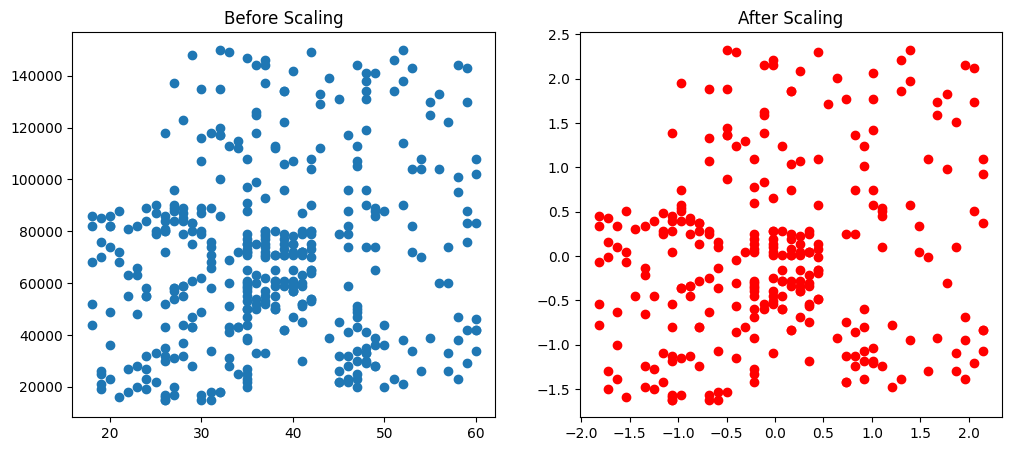

In [17]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(x = 'Age', y = 'EstimatedSalary', data = df)
ax1.set_title("Before Scaling")
ax2.scatter(x= 'Age', y = 'EstimatedSalary', data = x_train_scaled_df, color='red')
ax2.set_title("After Scaling")
plt.show()

In [18]:
# We can see thet there is no difference in the distribution which even should not be,as expected, scale is changed.
# We can see on x-axis

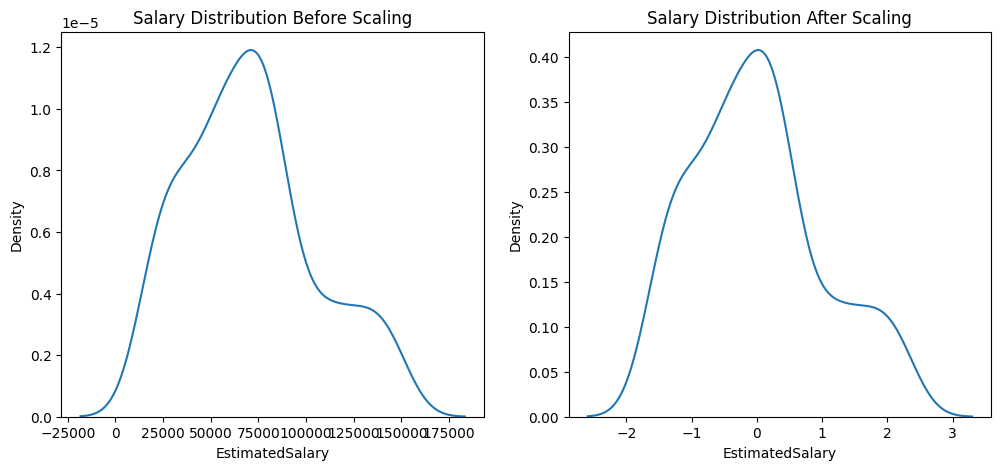

In [19]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling

ax1.set_title('Salary Distribution Before Scaling')
sns.kdeplot(x_train['EstimatedSalary'], ax=ax1)

# after scaling

ax2.set_title('Salary Distribution After Scaling')
sns.kdeplot(x_train_scaled_df['EstimatedSalary'], ax =ax2)
plt.show()

# Why scaling is important??

In [20]:
from sklearn.linear_model import LogisticRegression

In [43]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()

In [44]:
lr.fit(x_train, y_train)    # Training with unscaled dataframe

LogisticRegression()

In [45]:
lr_scaled.fit(x_train_scaled_df, y_train)    # Training with scaled dataframe

LogisticRegression()

In [46]:
y_pred_unscaled = lr.predict(x_test)
y_pred_scaled = lr_scaled.predict(x_test_scaled_df)

In [47]:
# Getting accuracy scored of both, scaled and unscaled.

from sklearn.metrics import accuracy_score

In [48]:
accuracy_unscaled = accuracy_score(y_pred_unscaled, y_test)
accuracy_scaled = accuracy_score(y_pred_scaled, y_test)

print(f"Accuracy on unscaled dataframe = {accuracy_unscaled}.\nAccuracy on scaled dataframe = {accuracy_scaled}.")

Accuracy on unscaled dataframe = 0.6166666666666667.
Accuracy on scaled dataframe = 0.775.


# We can clearly see the difference in the accuracy we are getting with scaled data and unscaled data.

Note: There's no effect of scaling on **Decision tree**. Let's try with **Decision tree** model.

In [61]:
from sklearn.tree import DecisionTreeClassifier

In [62]:
dt = DecisionTreeClassifier()
dt_scaled = DecisionTreeClassifier()

In [63]:
dt.fit(x_train, y_train)              # Unscaled
dt_scaled.fit(x_train_scaled_df, y_train)    # Scaled

DecisionTreeClassifier()

In [64]:
y_pred_unscaled = dt.predict(x_test)
y_pred_scaled = dt_scaled.predict(x_test_scaled_df)

In [65]:
accuracy_unscaled = accuracy_score(y_pred_unscaled, y_test)
accuracy_scaled = accuracy_score(y_pred_scaled, y_test)

print(f"Accuracy unscaled = {accuracy_unscaled}\nAccuracy Scaled = {accuracy_scaled}")

Accuracy unscaled = 0.7916666666666666
Accuracy Scaled = 0.8


# We can see, there's no difference in accuracy when we train decision tree model on scaled and unscaled data.

# What happens to outliers?
Outliers remains as it is. There'll be no effect to outliers after scaling, so we always need to deal with it seperately,

# Which algorithm requires `scaling`?
1) K- Means
2) KNearestNeighbors
3) Principal Components Analysis
4) Artificial Neural Network
5) Gradient Descent

# Which algorithm doesn't requires `scaling`?(Scaling doesn't make any difference whether we perform it or not.)
1) Decision Tree
2) Random Forest
3) Gradiend Boost
4) XG Boost


# Day 25: Feature scaling(Normalization).(Not getting clear in CampusX's video)
# Day 26: Encoding categorical data